In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('../data/processed/data_clean.csv', parse_dates= ['InvoiceDate'])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 535187 entries, 0 to 535186
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    535187 non-null  str           
 1   StockCode    535187 non-null  str           
 2   Description  535187 non-null  str           
 3   Quantity     535187 non-null  int64         
 4   InvoiceDate  535187 non-null  datetime64[us]
 5   UnitPrice    535187 non-null  float64       
 6   CustomerID   401604 non-null  float64       
 7   Country      535187 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 32.7 MB


##  Question 1 : Quels sont les 5 pays qui génèrent le plus de chiffre d'affaires ?

In [12]:
df['CA'] = df['Quantity'] * df['UnitPrice']
top_ca = df.groupby(['Country'])['CA'].sum().sort_values(ascending=False)
top_ca

Country
United Kingdom          8167128.184
Netherlands              284661.540
EIRE                     262993.380
Germany                  221509.470
France                   197317.110
Australia                137009.770
Switzerland               56363.050
Spain                     54756.030
Belgium                   40910.960
Sweden                    36585.410
Japan                     35340.620
Norway                    35163.460
Portugal                  29302.970
Finland                   22326.740
Channel Islands           20076.390
Denmark                   18768.140
Italy                     16890.510
Cyprus                    12858.760
Austria                   10154.320
Hong Kong                  9908.240
Singapore                  9120.390
Israel                     7901.970
Poland                     7213.140
Unspecified                4740.940
Greece                     4710.520
Iceland                    4310.000
Canada                     3666.380
Malta               

C:\Users\mbenk\AppData\Local\Temp\ipykernel_5932\1698080478.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_ca.reset_index().head(5), x='Country', y='CA', palette='viridis')


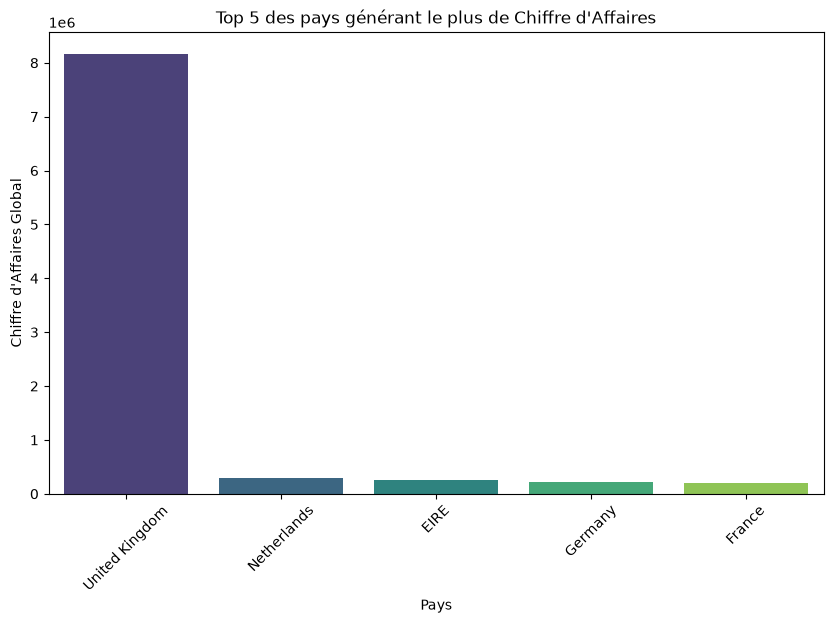

In [13]:
plt.figure(figsize=(10, 6))
sns.barplot(data=top_ca.reset_index().head(5), x='Country', y='CA', palette='viridis')
plt.title('Top 5 des pays générant le plus de Chiffre d\'Affaires')
plt.xlabel('Pays')
plt.ylabel('Chiffre d\'Affaires Global')
plt.xticks(rotation=45)
plt.savefig('../figures/top_5_pays_ca.png', dpi=150, bbox_inches='tight')
plt.show()

**Type :** Diagramme en barres, idéal pour comparer des valeurs quantitatives par catégorie.

**Conclusion :** Selon l'analyse, les pays ayant généré le plus grand chiffre d'affaire sont : 

**1 - United Kingdom**

**2 - Netherlands**

**3 - EIRE**

**4 - Germany**

**5 - France**

## Question 2 : Quelle est l'évolution du volume des ventes au fil des mois ?

In [14]:
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M').astype(str)
monthly_sales = df.groupby('YearMonth')['Quantity'].sum().reset_index()
monthly_sales

,YearMonth,Quantity
0,2010-12,342135
1,2011-01,301161
2,2011-02,276552
3,2011-03,350869
4,2011-04,292145
5,2011-05,381228
6,2011-06,342389
7,2011-07,393633
8,2011-08,408005
9,2011-09,555818


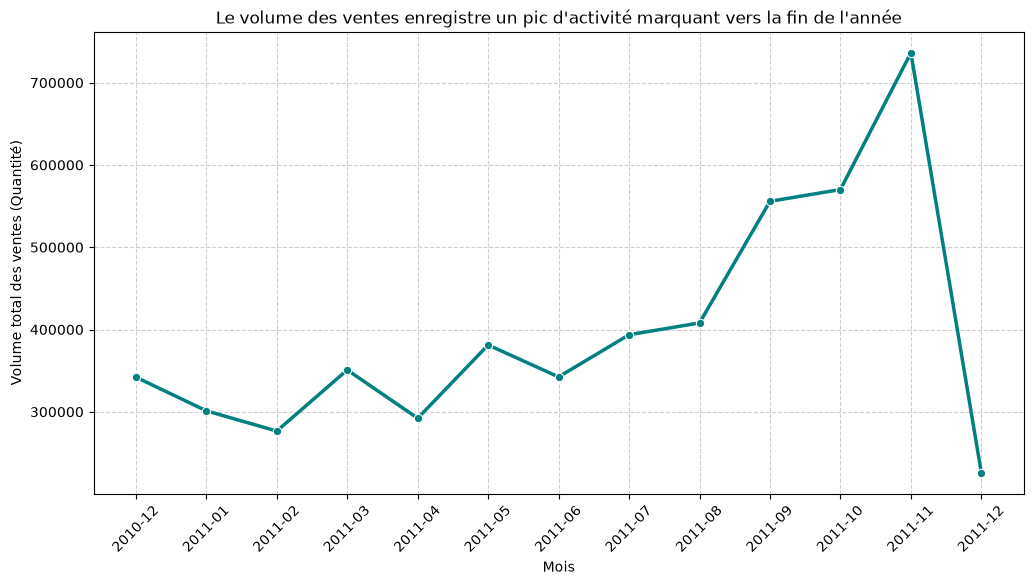

In [15]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.lineplot(
    data=monthly_sales, 
    x='YearMonth', 
    y='Quantity', 
    marker='o', 
    color='teal', 
    linewidth=2.5,
    ax=ax
)
ax.set_title("Le volume des ventes enregistre un pic d'activité marquant vers la fin de l'année")
ax.set_xlabel("Mois")
ax.set_ylabel("Volume total des ventes (Quantité)")
plt.xticks(rotation=45)
ax.grid(True, linestyle='--', alpha=0.6)
fig.savefig('../figures/evolution_volume_ventes_mois.png', dpi=150, bbox_inches='tight')

plt.show()

**Type :** Graphique en ligne, idéal pour suivre l'évolution d'une métrique quantitative au fil du temps.

**Conclusion :** L'analyse temporelle montre une forte augmentation du volume des ventes à l'approche de la fin d'année, suivie d'une baisse prononcée, ce qui laisse pensé que l'augmentation est liée aux périodes de fêtes.

## Question 3 : Quel est le panier moyen par commande et observe-t-on des variations selon les pays ?

In [16]:
df_panier = df.groupby(['InvoiceNo', 'Country'], as_index=False)['CA'].sum()
panier_moyen_pays = df_panier.groupby('Country')['CA'].mean().reset_index()
panier_moyen_pays = panier_moyen_pays.sort_values(by='CA', ascending=False).head(5)
panier_moyen_pays


,Country,CA
24,Netherlands,2818.431089
0,Australia,1985.648841
21,Lebanon,1693.880000
20,Japan,1262.165000
4,Brazil,1143.600000


C:\Users\mbenk\AppData\Local\Temp\ipykernel_5932\993532805.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


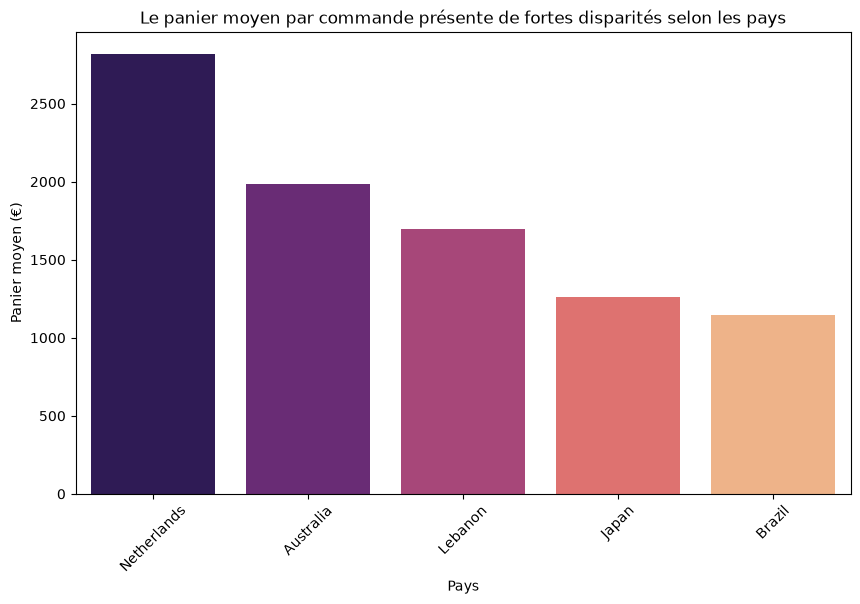

In [17]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=panier_moyen_pays, 
    x='Country', 
    y='CA', 
    palette='magma', 
    ax=ax
)
ax.set_title("Le panier moyen par commande présente de fortes disparités selon les pays")
ax.set_xlabel("Pays")
ax.set_ylabel("Panier moyen (€)")
plt.xticks(rotation=45)

fig.savefig('../figures/panier_moyen_par_pays.png', dpi=150, bbox_inches='tight')
plt.show()

**Type :** Diagramme en barres, idéal pour comparer des valeurs moyennes par catégorie.

**Conclusion :** L'analyse du panier moyen révèle que certains pays génèrent des commandes unitaires nettement plus élevées que d'autres, démontrant un comportement d'achat et un pouvoir d'achat hétérogène selon les marchés géographiques.

## Question 4 : Quels sont les produits ou articles qui subissent le plus d'annulations (factures commençant par "C") ?

In [18]:
df_ventes = df[df['InvoiceNo'].astype(str).str.startswith('C')].copy()
df_annulations = df[df['InvoiceNo'].astype(str).str.startswith('C')].copy()
df_self_join = pd.merge(
    df_annulations, 
    df_ventes, 
    on=['CustomerID', 'StockCode'], 
    suffixes=('_annul', '_vente')
)
top_returns = df_annulations.groupby('Description')['Quantity'].sum().abs().reset_index()
top_returns = top_returns.sort_values(by='Quantity', ascending=False).head(5)
top_returns

,Description,Quantity
1184,"PAPER CRAFT , LITTLE BIRDIE",80995
1025,MEDIUM CERAMIC TOP STORAGE JAR,74494
1459,ROTATING SILVER ANGELS T-LIGHT HLDR,9376
1093,Manual,4066
592,FAIRY CAKE FLANNEL ASSORTED COLOUR,3150


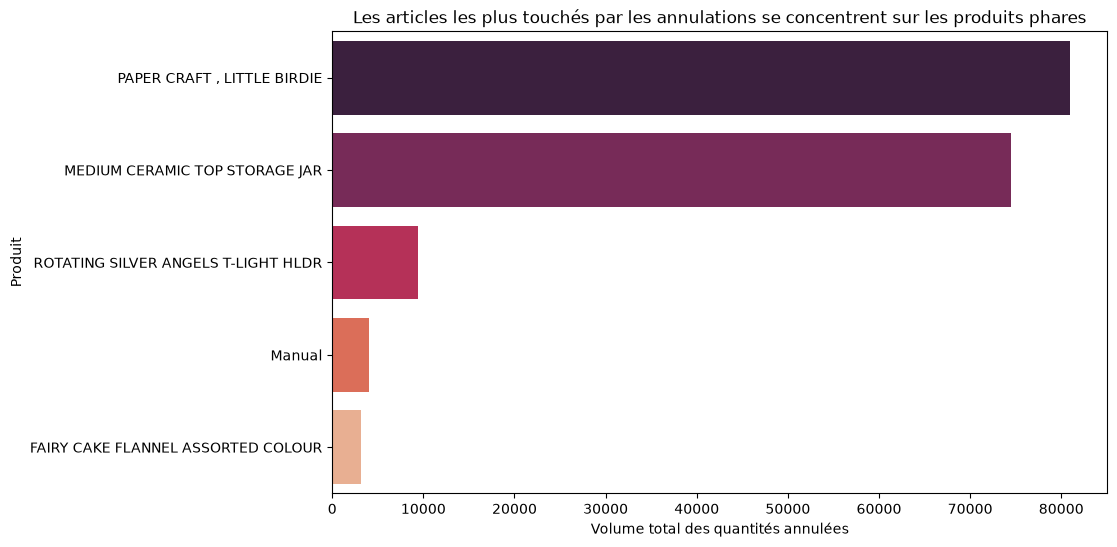

In [19]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=top_returns, 
    x='Quantity', 
    y='Description', 
    hue='Description',
    legend=False,
    palette='rocket', 
    ax=ax
)
ax.set_title("Les articles les plus touchés par les annulations se concentrent sur les produits phares")
ax.set_xlabel("Volume total des quantités annulées")
ax.set_ylabel("Produit")

fig.savefig('../figures/top_produits_annules.png', dpi=150, bbox_inches='tight')

plt.show()

**Type :** Diagramme en barres horizontales, idéal pour comparer des volumes par catégorie lorsque les libellés textuels sont longs.

**Conclusion :** L'analyse montre que les volumes de retours les plus élevés concernent principalement les articles à fort volume de vente initial, confirmant que le taux d'annulation est directement corrélé à la popularité des produits sur la période.